In [2]:
# 그래프관련 import 
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 프로그램 
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier # 분류 클래스
from sklearn.neighbors import KNeighborsRegressor # 예측 클래스
from sklearn.linear_model import LinearRegression # 예측 클래스
from sklearn.metrics import mean_absolute_error # 평균절대오차 오차범위 클래스
from sklearn.preprocessing import StandardScaler  # 정규화 클래스
from sklearn.model_selection import train_test_split

In [3]:
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
     21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
     22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
     27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
     36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
     40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
     )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
     110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
     130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
     197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
     514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
     820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
     1000.0, 1000.0]
     )

In [4]:
# 데이터 전처리 완료
# 학습데이터, 테스트데이터 분리
train_data,test_data,train_label,test_label = train_test_split(perch_length,perch_weight)
train_data 

array([15. , 24. , 25. , 21.3, 32.8, 36. , 19.6, 27.3, 13.7, 28.7, 39. ,
       24. , 27.5, 26.5, 18. , 22. , 23.5, 40. , 42. , 40. , 21. , 23. ,
       34.5, 43. , 22.5, 18.7, 39. , 44. , 40. , 30. , 36.5, 24.6, 22.7,
       37. , 40. , 16.2, 17.4, 19. , 25.6, 22. , 43.5, 35. ])

In [5]:
train_data = train_data.reshape(-1,1) # 2차원 배열로 변경해야함. 이유 : 길이, 무게, 두께 등등의 컬럼이 추가되기에 2차원 데이터로 변경을 위해서.
# train_data

test_data = test_data.reshape(-1,1)
test_data

array([[22.5],
       [22. ],
       [43. ],
       [28. ],
       [39. ],
       [37. ],
       [20. ],
       [27.5],
       [22. ],
       [21. ],
       [21. ],
       [22. ],
       [ 8.4],
       [27.5]])

In [6]:
# 데이터 학습
lr = LinearRegression()
lr.fit(train_data,train_label)

# 데이터 예측 
predict = lr.predict(test_data)
print('예측무게 :', predict)

# 정확도 
score = lr.score(train_data,train_label)
score2 = lr.score(test_data,test_label)
print('train정확도 :', score)
print('test정확도 :', score2)

# 기울기, y절편 : LinearRegression 사용할 때만 출력 가능
print('기울기 :', lr.coef_) # 예측을 완료한 상태에서 기울기를 알 수 있음.
print('y절편 :', lr.intercept_)

예측무게 : [ 179.19020756  160.28448464  954.3248475   387.15315974  803.0790641
  727.4561724    84.66159294  368.24743682  160.28448464  122.47303879
  122.47303879  160.28448464 -353.95117893  368.24743682]
train정확도 : 0.9340870538654238
test정확도 : 0.8536032237094956
기울기 : [37.81144585]
y절편 : -671.5673240716062


In [7]:
# KNeighborRegressor 50cm -> 1000g , 100cm -> 1000g 예측
# 50cm 농어 예측 50cm -> 1173 , 100cm -> 2951g얘측 
# predict2 = lr.predict([[50]])
# print("예측무게 :", predict2)

predict2 = lr.predict([[100]])
print("예측무게 :", predict2)

예측무게 : [3109.57726098]


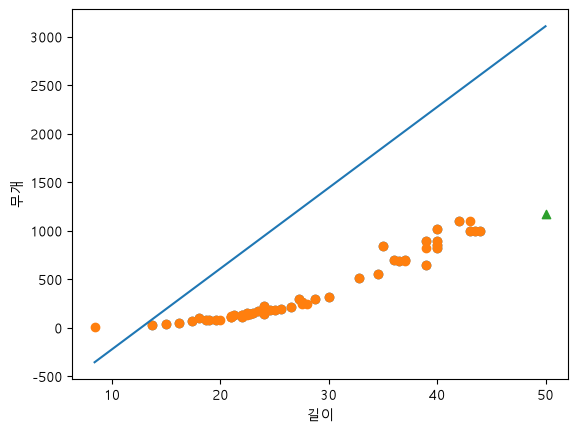

In [8]:
# 산점도 그래프 

plt.scatter(train_data,train_label)
plt.scatter(perch_length,perch_weight)
plt.scatter(50,1173,marker='^')
# plt.scatter(100,2951,marker='*')
plt.plot([8.4,50],[8.4*lr.coef_+lr.intercept_,100*lr.coef_+lr.intercept_]) # 선 그래프 
plt.xlabel('길이')
plt.ylabel('무개')
plt.show()

In [9]:
# 길이 입력받아, 무게를 예측하고, 산점도 그래프에 표시하시오.
# 농어길이를 입력하세요. 예)52, 5
in_data = input(' 농어길이를 입력하세요. 예)52, 5')
in_data = float(in_data)52

predict = lr.predict([[in_data]])
print('예측무게 : ',predict)

예측무게 :  [1294.62786015]


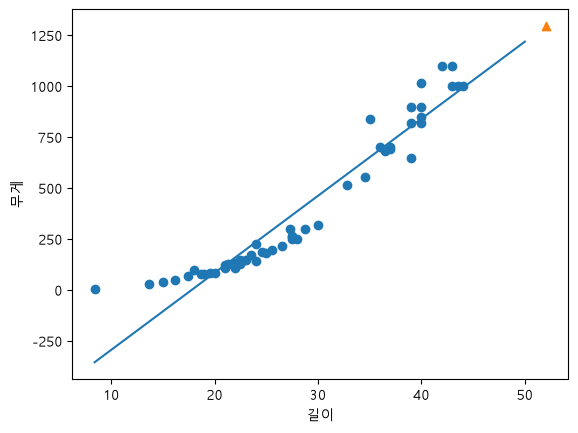

In [10]:
# 산점도 그래프에 표시
# 선 그래프도 함께 표시
# 산점도 그래프
plt.scatter(perch_length,perch_weight)
plt.scatter(in_data,predict, marker='^')
plt.plot([8.4,50],[8.4*lr.coef_+lr.intercept_,50*lr.coef_+lr.intercept_])  # 선그래프
plt.xlabel("길이")
plt.ylabel("무게")
plt.show()